<div align="center">
    <img src="Global%20YouTube%20Creators%20Analysis.png" width="100%">
</div>



## 📌 Executive Summary
This project presents an end-to-end data exploration and feature engineering workflow on the **Global YouTube Statistics** dataset (995 creators across 28 attributes). The analysis examines subscriber distributions, content categorization, view efficiency, and channel growth metrics.

## 📑 Table of Contents
1. [Environment Setup & Ingestion](#1-environment-setup--ingestion)
2. [Data Cleaning & Preprocessing](#2-data-cleaning--preprocessing)
3. [Feature Engineering](#3-feature-engineering)
4. [Univariate Data Analysis](#4-univariate-data-analysis)
5. [Key Takeaways & Insights](#5-key-takeaways--insights)

## LIBRARY IMPORTING

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

YOUTUBE_RED = "#E62117"
BLACK = "#222222"

df = pd.read_csv(r"C:\DATA ANALYTICS\DA WITH PYTHON\Global YouTube Statistics.csv",encoding="latin1")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (995, 28)


,rank,Youtuber,subscribers,video views,category,Title,uploads,Country,Abbreviation,channel_type,...,subscribers_for_last_30_days,created_year,created_month,created_date,Gross tertiary education enrollment (%),Population,Unemployment rate,Urban_population,Latitude,Longitude
0,1,T-Series,245000000,2.280000e+11,Music,T-Series,20082,India,IN,Music,...,2000000.0,2006.0,Mar,13.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880
1,2,YouTube Movies,170000000,0.000000e+00,Film & Animation,youtubemovies,1,United States,US,Games,...,NaN,2006.0,Mar,5.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
2,3,MrBeast,166000000,2.836884e+10,Entertainment,MrBeast,741,United States,US,Entertainment,...,8000000.0,2012.0,Feb,20.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
3,4,Cocomelon - Nursery Rhymes,162000000,1.640000e+11,Education,Cocomelon - Nursery Rhymes,966,United States,US,Education,...,1000000.0,2006.0,Sep,1.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
4,5,SET India,159000000,1.480000e+11,Shows,SET India,116536,India,IN,Entertainment,...,1000000.0,2006.0,Sep,20.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 995 entries, 0 to 994
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   rank                                     995 non-null    int64  
 1   Youtuber                                 995 non-null    str    
 2   subscribers                              995 non-null    int64  
 3   video views                              995 non-null    float64
 4   category                                 949 non-null    str    
 5   Title                                    995 non-null    str    
 6   uploads                                  995 non-null    int64  
 7   Country                                  873 non-null    str    
 8   Abbreviation                             873 non-null    str    
 9   channel_type                             965 non-null    str    
 10  video_views_rank                         994 non-null    floa

In [31]:
display(df.describe(include="all"))

,rank,Youtuber,subscribers,video views,category,Title,uploads,Country,Abbreviation,channel_type,...,subscribers_for_last_30_days,created_year,created_month,created_date,Gross tertiary education enrollment (%),Population,Unemployment rate,Urban_population,Latitude,Longitude
count,995.00000,995,9.950000e+02,9.950000e+02,949,995,995.000000,873,873,965,...,6.580000e+02,990.000000,990,990.000000,872.000000,8.720000e+02,872.000000,8.720000e+02,872.000000,872.000000
unique,NaN,995,NaN,NaN,18,992,NaN,49,49,14,...,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,T-Series,NaN,NaN,Entertainment,Like Nastya Vlog,NaN,United States,US,Entertainment,...,NaN,NaN,Jan,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,NaN,NaN,241,2,NaN,313,313,304,...,NaN,NaN,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,498.00000,NaN,2.298241e+07,1.103954e+10,NaN,NaN,9187.125628,NaN,NaN,NaN,...,3.490791e+05,2012.630303,NaN,15.746465,63.627752,4.303873e+08,9.279278,2.242150e+08,26.632783,-14.128146
std,287.37606,NaN,1.752611e+07,1.411084e+10,NaN,NaN,34151.352254,NaN,NaN,NaN,...,6.143554e+05,4.512503,NaN,8.777520,26.106893,4.727947e+08,4.888354,1.546874e+08,20.560533,84.760809
min,1.00000,NaN,1.230000e+07,0.000000e+00,NaN,NaN,0.000000,NaN,NaN,NaN,...,1.000000e+00,1970.000000,NaN,1.000000,7.600000,2.025060e+05,0.750000,3.558800e+04,-38.416097,-172.104629
25%,249.50000,NaN,1.450000e+07,4.288145e+09,NaN,NaN,194.500000,NaN,NaN,NaN,...,1.000000e+05,2009.000000,NaN,8.000000,36.300000,8.335541e+07,5.270000,5.590832e+07,20.593684,-95.712891
50%,498.00000,NaN,1.770000e+07,7.760820e+09,NaN,NaN,729.000000,NaN,NaN,NaN,...,2.000000e+05,2013.000000,NaN,16.000000,68.000000,3.282395e+08,9.365000,2.706630e+08,37.090240,-51.925280
75%,746.50000,NaN,2.460000e+07,1.355470e+10,NaN,NaN,2667.500000,NaN,NaN,NaN,...,4.000000e+05,2016.000000,NaN,23.000000,88.200000,3.282395e+08,14.700000,2.706630e+08,37.090240,78.962880


In [32]:
df.columns = (df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True))
print(df.columns.tolist())

['rank', 'youtuber', 'subscribers', 'video_views', 'category', 'title', 'uploads', 'country', 'abbreviation', 'channel_type', 'video_views_rank', 'country_rank', 'channel_type_rank', 'video_views_for_the_last_30_days', 'lowest_monthly_earnings', 'highest_monthly_earnings', 'lowest_yearly_earnings', 'highest_yearly_earnings', 'subscribers_for_last_30_days', 'created_year', 'created_month', 'created_date', 'gross_tertiary_education_enrollment_(%)', 'population', 'unemployment_rate', 'urban_population', 'latitude', 'longitude']


# DATA PREPROCESSING

## Missing Value Handling

In [33]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing[missing["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
subscribers_for_last_30_days,337,33.87
latitude,123,12.36
urban_population,123,12.36
longitude,123,12.36
population,123,12.36
gross_tertiary_education_enrollment_(%),123,12.36
unemployment_rate,123,12.36
abbreviation,122,12.26
country,122,12.26
country_rank,116,11.66


In [34]:
df["category"] = df["category"].fillna("Unknown")
df["channel_type"] = df["channel_type"].fillna("Unknown")

print("Missing values after category handling:")
display(df[["category", "channel_type"]].isnull().sum())

Missing values after category handling:


category        0
channel_type    0
dtype: int64

Category and channel-type summaries can include an explicit unknown group without inventing values. Other missing fields remain available for careful filtering during relevant analyses.

In [35]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate channel names:",df["youtuber"].duplicated().sum())

Duplicate rows: 0
Duplicate channel names: 0


In [36]:
numeric_cols = [
    "rank",
    "subscribers",
    "video_views",
    "uploads",
    "video_views_for_the_last_30_days",
    "subscribers_for_last_30_days",
    "highest_yearly_earnings"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
rank,995.0,4.980000e+02,2.873761e+02,1.0,2.495000e+02,4.980000e+02,7.465000e+02,9.950000e+02
subscribers,995.0,2.298241e+07,1.752611e+07,12300000.0,1.450000e+07,1.770000e+07,2.460000e+07,2.450000e+08
video_views,995.0,1.103954e+10,1.411084e+10,0.0,4.288145e+09,7.760820e+09,1.355470e+10,2.280000e+11
uploads,995.0,9.187126e+03,3.415135e+04,0.0,1.945000e+02,7.290000e+02,2.667500e+03,3.013080e+05
video_views_for_the_last_30_days,939.0,1.756103e+08,4.163782e+08,1.0,2.013750e+07,6.408500e+07,1.688265e+08,6.589000e+09
subscribers_for_last_30_days,658.0,3.490791e+05,6.143554e+05,1.0,1.000000e+05,2.000000e+05,4.000000e+05,8.000000e+06
highest_yearly_earnings,995.0,7.081814e+06,1.379704e+07,0.0,5.217500e+05,2.600000e+06,7.300000e+06,1.634000e+08


The selected metrics are ready for numerical analysis, subject to checking for invalid values and extreme observations.

## Outlier Analysis

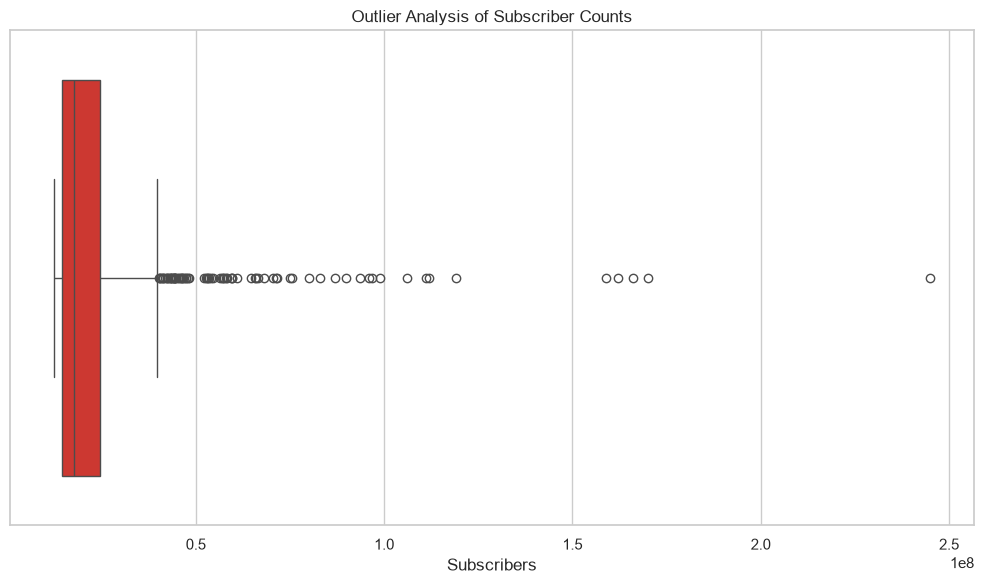

In [37]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="subscribers",
    color=YOUTUBE_RED
)

plt.title("Outlier Analysis of Subscriber Counts")
plt.xlabel("Subscribers")
plt.tight_layout()
plt.show()

Subscriber counts are highly uneven across channels. Very large channels may be genuine observations and should be retained unless there is evidence of incorrect data.

## Feature Engineering

In [38]:
df["views_per_subscriber"] = (df["video_views"] /df["subscribers"].replace(0, np.nan))

calculates accumulated views per subscriber. It is a rough descriptive ratio, not an engagement rate.

In [39]:
df["average_views_per_upload"] = (df["video_views"] /df["uploads"].replace(0, np.nan))

compares lifetime channel views with total uploads. It does not mean every video receives that number of views.

In [40]:
df["recent_subscriber_growth_pct"] = (
    df["subscribers_for_last_30_days"] /
    (
        df["subscribers"] -
        df["subscribers_for_last_30_days"]
    )
) * 100

df.loc[
    (df["subscribers"] <= df["subscribers_for_last_30_days"])
    | (df["subscribers_for_last_30_days"] < 0),
    "recent_subscriber_growth_pct"
] = np.nan

These features allow us to compare channels using ratios in addition to absolute counts. They should be interpreted alongside channel size, reporting period, and data quality.

# UNIVARIATE ANALYSIS

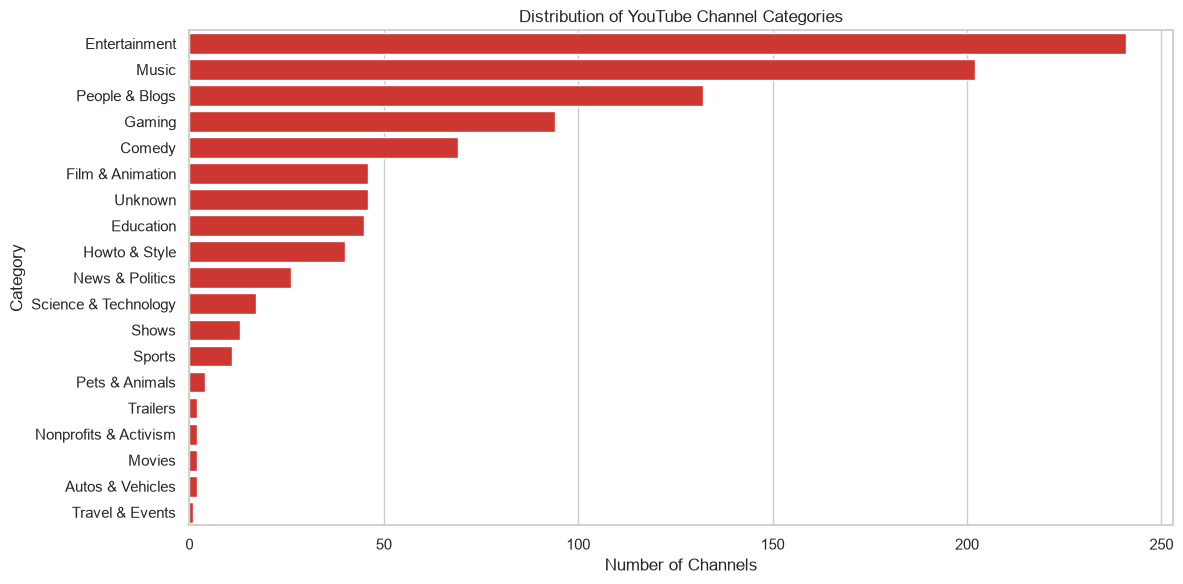

In [41]:
plt.figure(figsize=(12, 6))

order = df["category"].value_counts().index

sns.countplot(
    data=df,
    y="category",
    order=order,
    color="#E62117"
)

plt.title("Distribution of YouTube Channel Categories")
plt.xlabel("Number of Channels")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Entertainment is the most represented category with 241 channels, followed by Music with 202. This describes representation in the dataset, not necessarily the popularity of each category across all of YouTube.

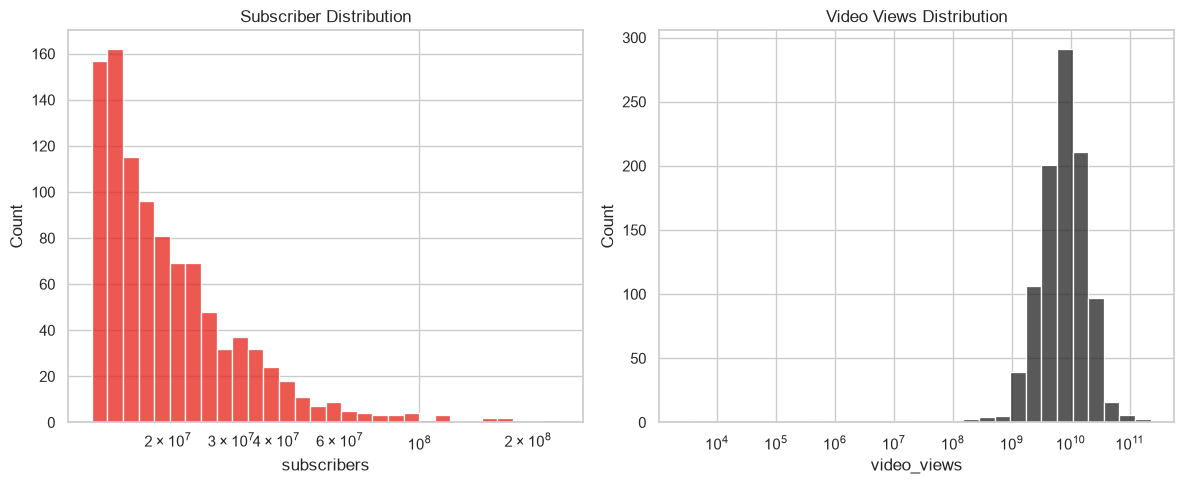

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df,
    x="subscribers",
    bins=30,
    log_scale=(True, False),
    color=YOUTUBE_RED,
    ax=axes[0]
)
axes[0].set_title("Subscriber Distribution")

sns.histplot(
    data=df,
    x="video_views",
    bins=30,
    log_scale=(True, False),
    color=BLACK,
    ax=axes[1]
)
axes[1].set_title("Video Views Distribution")

plt.tight_layout()
plt.show()

Subscriber counts span a very wide range. A few exceptionally large channels can make the distribution strongly right-skewed, so a log-scale histogram is also useful.

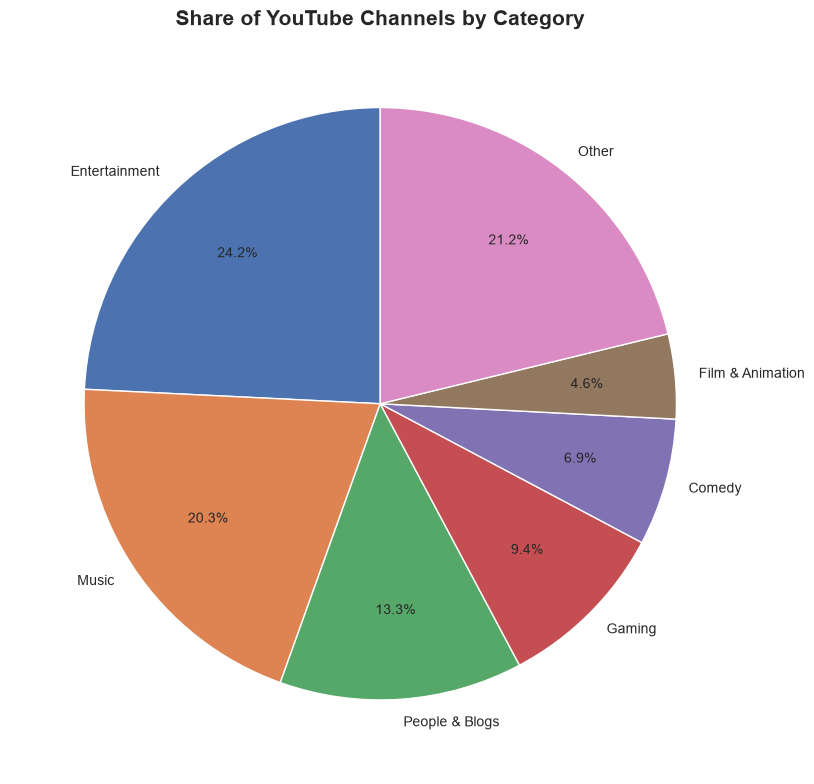

In [43]:

# Count channels by category
category_counts = df["category"].value_counts()

# Keep the top 6 categories and group the rest
top_categories = category_counts.head(6)
other_count = category_counts.iloc[6:].sum()

pie_data = pd.concat([
    top_categories,
    pd.Series({"Other": other_count})
])

plt.figure(figsize=(10, 8))

plt.pie(
    pie_data,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.7,
    labeldistance=1.08,
    textprops={"fontsize": 10},
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.title(
    "Share of YouTube Channels by Category",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


Entertainment and Music account for the largest individual category shares in this dataset.

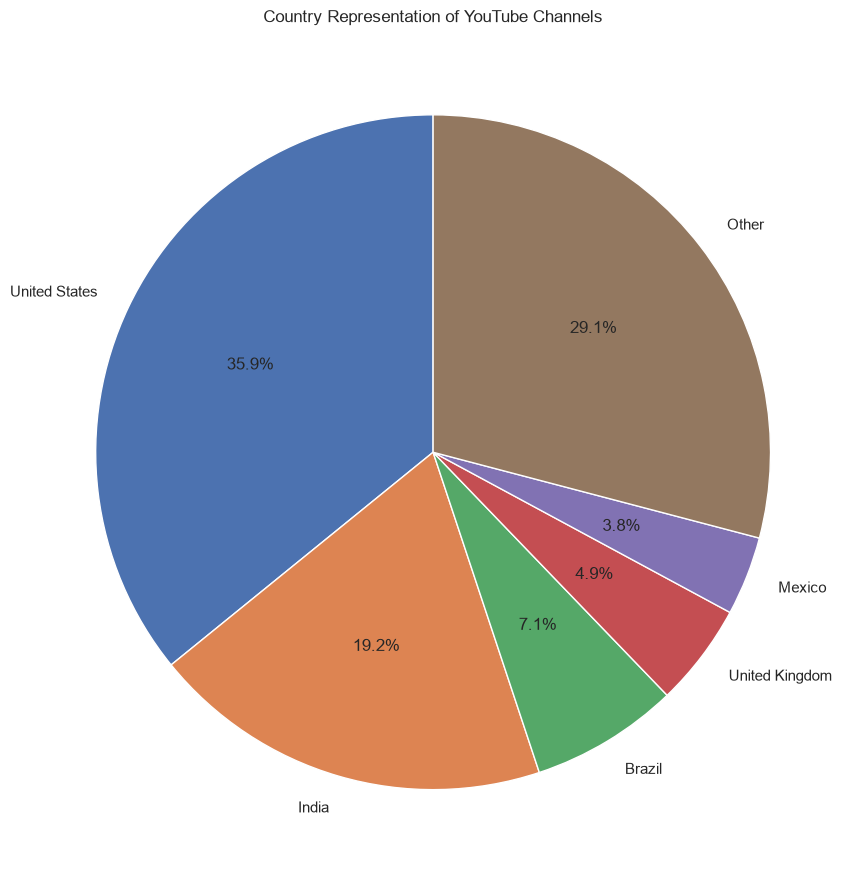

In [44]:
country_counts = df["country"].value_counts()

top5 = country_counts.head(5)
other_count = country_counts.iloc[5:].sum()

pie_data = pd.concat([
    top5,
    pd.Series({"Other": other_count})
])

plt.figure(figsize=(9, 9))

plt.pie(
    pie_data,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Country Representation of YouTube Channels")
plt.tight_layout()
plt.show()

The United States contributes 313 channels and India 168. These counts reflect country representation in the selected dataset, not the total number of creators in either country.

# BIVARIATE ANALYSIS

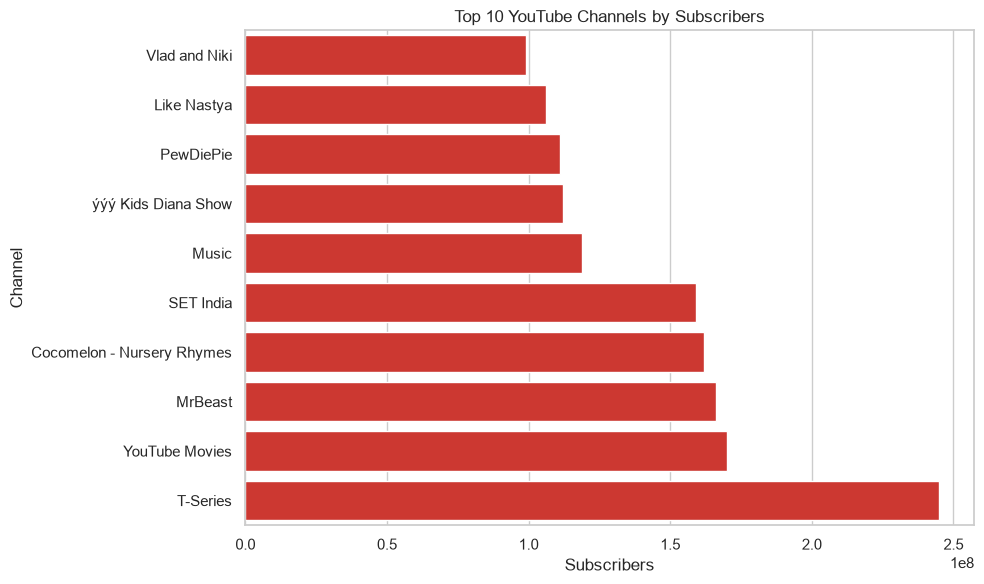

In [45]:
top_subscribers = (
    df.nlargest(10, "subscribers")
      .sort_values("subscribers")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_subscribers,
    x="subscribers",
    y="youtuber",
    color="#E62117"
)

plt.title("Top 10 YouTube Channels by Subscribers")
plt.xlabel("Subscribers")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

T-Series ranks first by subscribers in this dataset, with 245 million. YouTube Movies and MrBeast follow, with 170 million and 166 million, respectively.

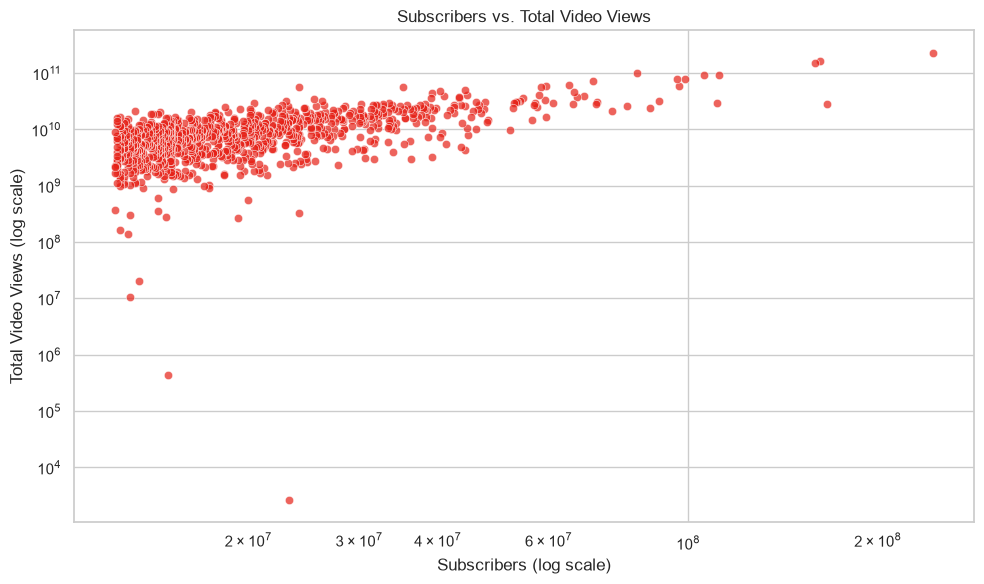

In [46]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="subscribers",
    y="video_views",
    alpha=0.7,
    color="#E62117"
)

plt.xscale("log")
plt.yscale("log")

plt.title("Subscribers vs. Total Video Views")
plt.xlabel("Subscribers (log scale)")
plt.ylabel("Total Video Views (log scale)")
plt.tight_layout()
plt.show()

Subscriber count and total video views have a moderate positive monotonic association in the dataset. Larger subscriber counts tend to accompany larger lifetime view counts, although there are exceptions.

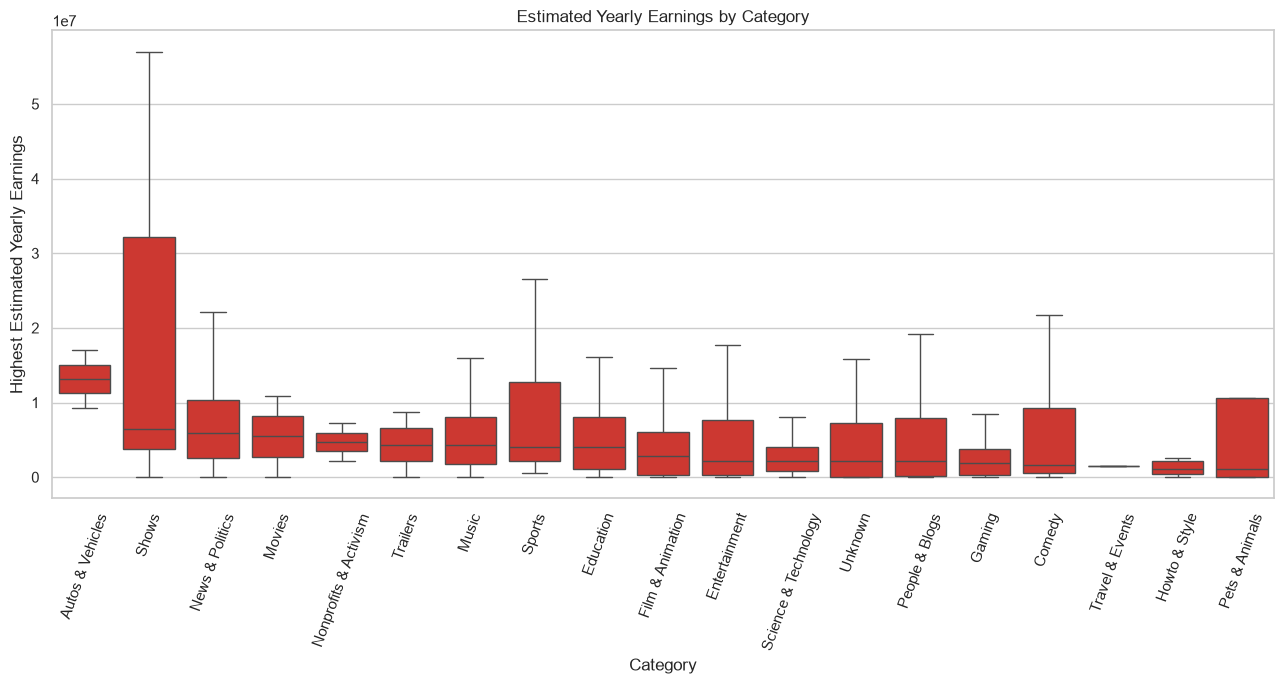

In [47]:
plt.figure(figsize=(13, 7))

category_order = (
    df.groupby("category")["highest_yearly_earnings"]
      .median()
      .sort_values(ascending=False)
      .index
)

sns.boxplot(
    data=df,
    x="category",
    y="highest_yearly_earnings",
    order=category_order,showfliers=False,
    color="#E62117"
)

plt.title("Estimated Yearly Earnings by Category")
plt.xlabel("Category")
plt.ylabel("Highest Estimated Yearly Earnings")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

Earnings estimates vary considerably within categories. Comparing medians and spreads is more informative about a typical channel than relying only on the highest-earning observation.

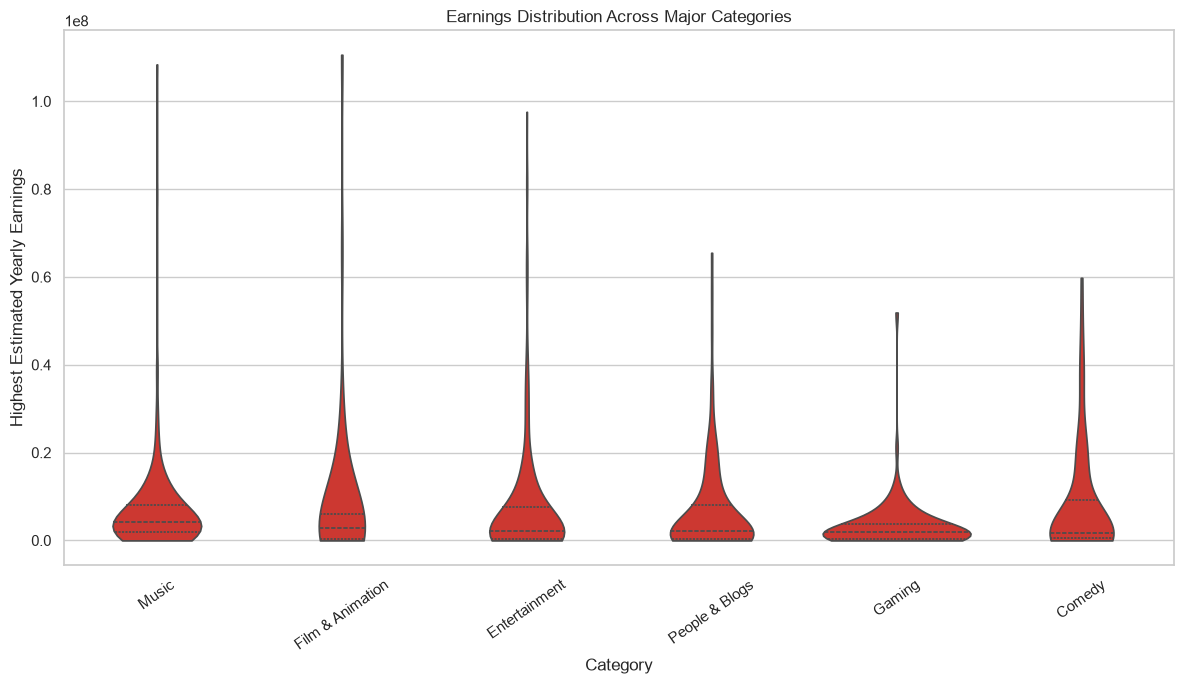

In [48]:
top_categories = (
    df["category"]
      .value_counts()
      .head(6)
      .index
)

violin_data = df[
    df["category"].isin(top_categories)
    & df["highest_yearly_earnings"].notna()
].copy()

plt.figure(figsize=(12, 7))

sns.violinplot(
    data=violin_data,
    x="category",
    y="highest_yearly_earnings",
    inner="quartile",
    cut=0,
    color="#E62117"
)

plt.title("Earnings Distribution Across Major Categories")
plt.xlabel("Category")
plt.ylabel("Highest Estimated Yearly Earnings")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

The violin plot reveals how earnings are distributed within the most represented categories. Wide sections indicate concentrations of observations at those earnings levels.

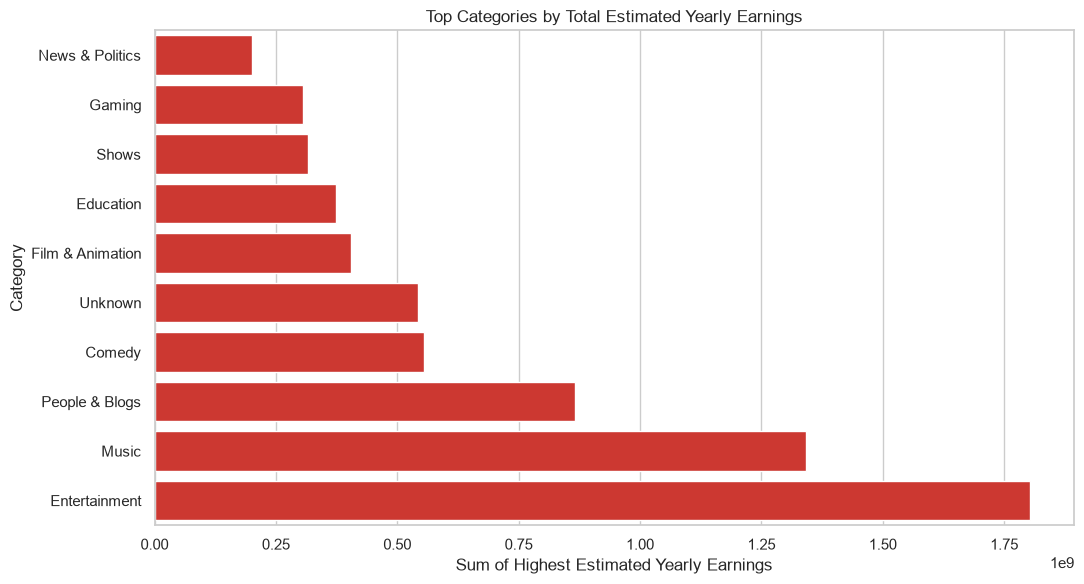

In [49]:
category_earnings = (
    df.dropna(subset=["category", "highest_yearly_earnings"])
      .groupby("category")
      .agg(
          channel_count=("youtuber", "count"),
          total_estimated_earnings=("highest_yearly_earnings", "sum"),
          median_estimated_earnings=("highest_yearly_earnings", "median")
      )
)

top_total = (
    category_earnings
      .nlargest(10, "total_estimated_earnings")
      .sort_values("total_estimated_earnings")
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_total.reset_index(),
    x="total_estimated_earnings",
    y="category",
    color="#E62117"
)

plt.title("Top Categories by Total Estimated Yearly Earnings")
plt.xlabel("Sum of Highest Estimated Yearly Earnings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Entertainment has the largest total of highest yearly earnings estimates among categories in this dataset. Median earnings should be examined separately to compare the typical channel.

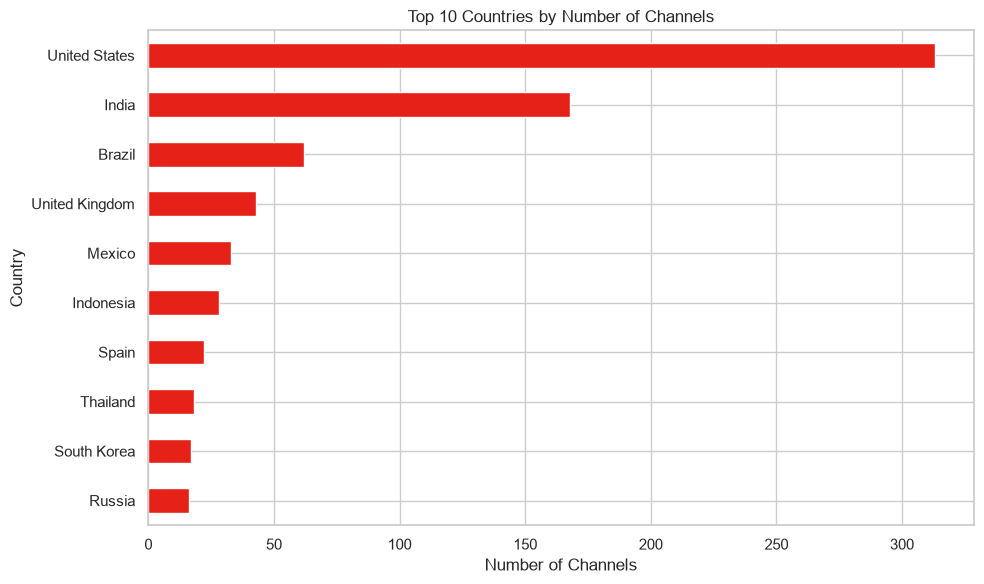

In [50]:
country_counts = (
    df["country"]
      .dropna()
      .value_counts()
      .head(10)
      .sort_values()
)

plt.figure(figsize=(10, 6))

country_counts.plot(
    kind="barh",
    color="#E62117"
)

plt.title("Top 10 Countries by Number of Channels")
plt.xlabel("Number of Channels")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

The United States has the highest representation, followed by India. Brazil ranks third. These results show the geographical distribution of the dataset's channels.

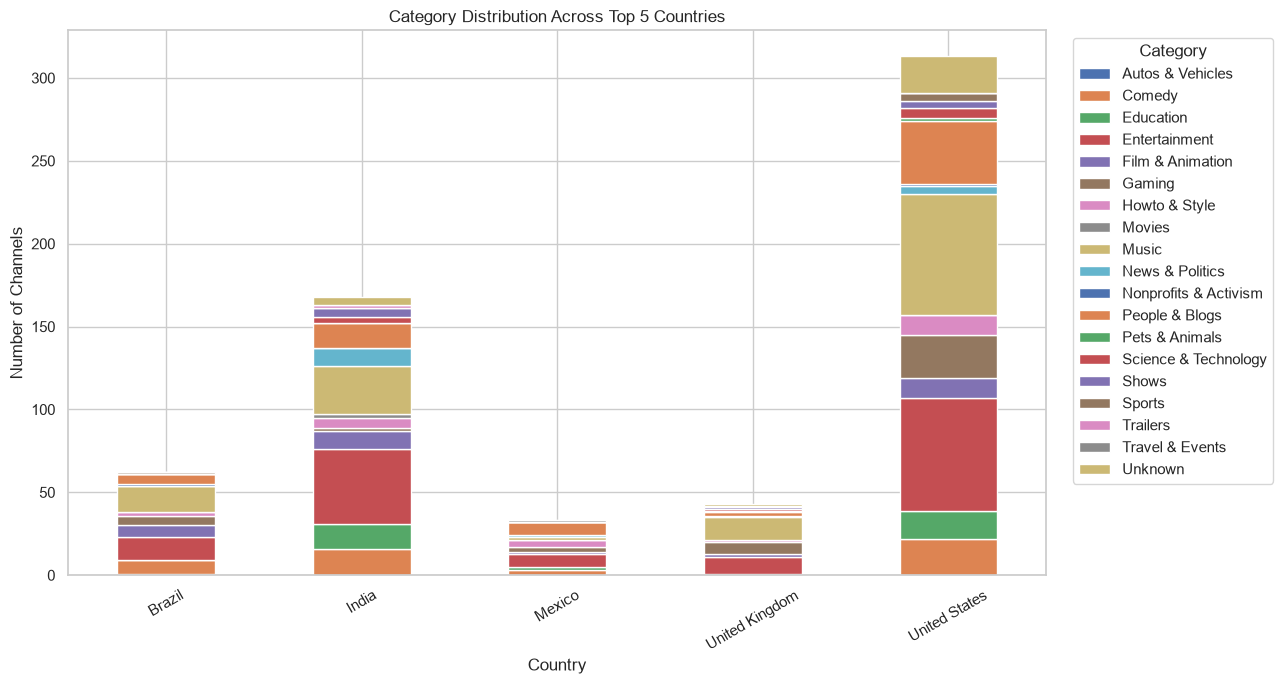

In [51]:
top_countries = df["country"].value_counts().head(5).index

country_category = df[
    df["country"].isin(top_countries)
    & df["category"].notna()
]

cross_tab = pd.crosstab(
    country_category["country"],
    country_category["category"]
)

cross_tab.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7)
)

plt.title("Category Distribution Across Top 5 Countries")
plt.xlabel("Country")
plt.ylabel("Number of Channels")
plt.xticks(rotation=30)
plt.legend(
    title="Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

The chart highlights differences in category representation between countries. Because the countries have different numbers of channels in the dataset, proportions may be more appropriate than raw counts for comparing category composition.

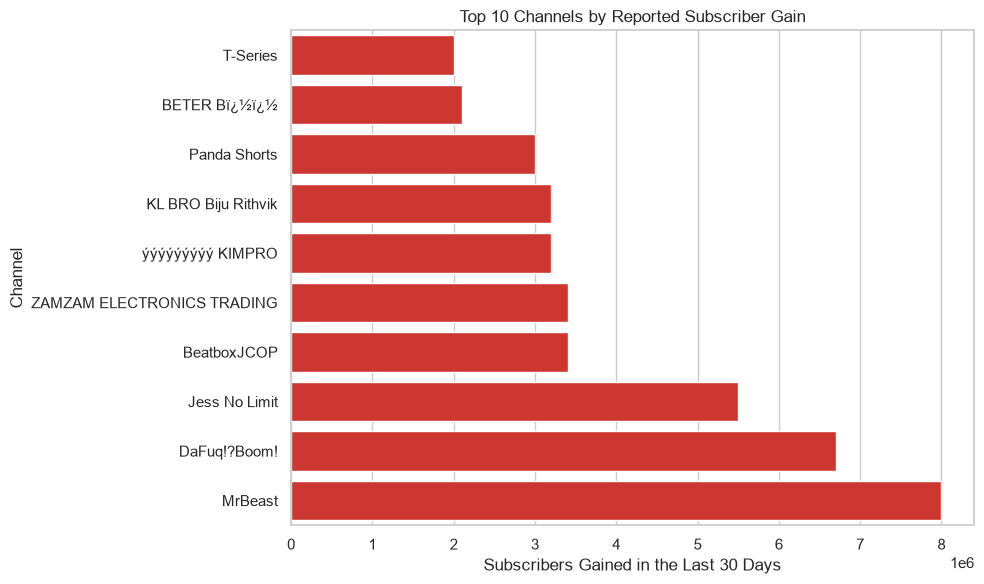

In [52]:
growth_data = (
    df.dropna(subset=["subscribers_for_last_30_days"])
      .nlargest(10, "subscribers_for_last_30_days")
      .sort_values("subscribers_for_last_30_days")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=growth_data,
    x="subscribers_for_last_30_days",
    y="youtuber",
    color="#E62117"
)

plt.title("Top 10 Channels by Reported Subscriber Gain")
plt.xlabel("Subscribers Gained in the Last 30 Days")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

MrBeast has the largest reported subscriber gain in the dataset, at 8 million, followed by DaFuq!?Boom! at 6.7 million. These are reported values for the dataset's observation period, not current live statistics.

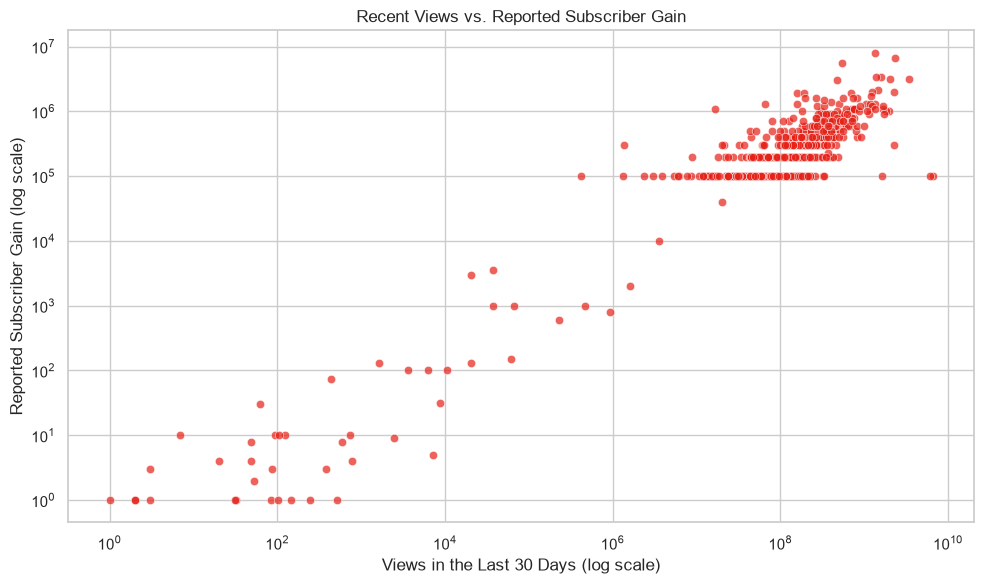

In [53]:
growth_pair = df.dropna(
    subset=[
        "video_views_for_the_last_30_days",
        "subscribers_for_last_30_days"
    ]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=growth_pair,
    x="video_views_for_the_last_30_days",
    y="subscribers_for_last_30_days",
    color="#E62117",
    alpha=0.7
)

plt.xscale("log")
plt.yscale("log")

plt.title("Recent Views vs. Reported Subscriber Gain")
plt.xlabel("Views in the Last 30 Days (log scale)")
plt.ylabel("Reported Subscriber Gain (log scale)")
plt.tight_layout()
plt.show()

Recent views and reported subscriber gain have a strong positive monotonic association in this dataset. This indicates that higher recent view counts tend to accompany larger subscriber gains, but it does not establish causation.

## MULTIVARIATE ANALYSIS

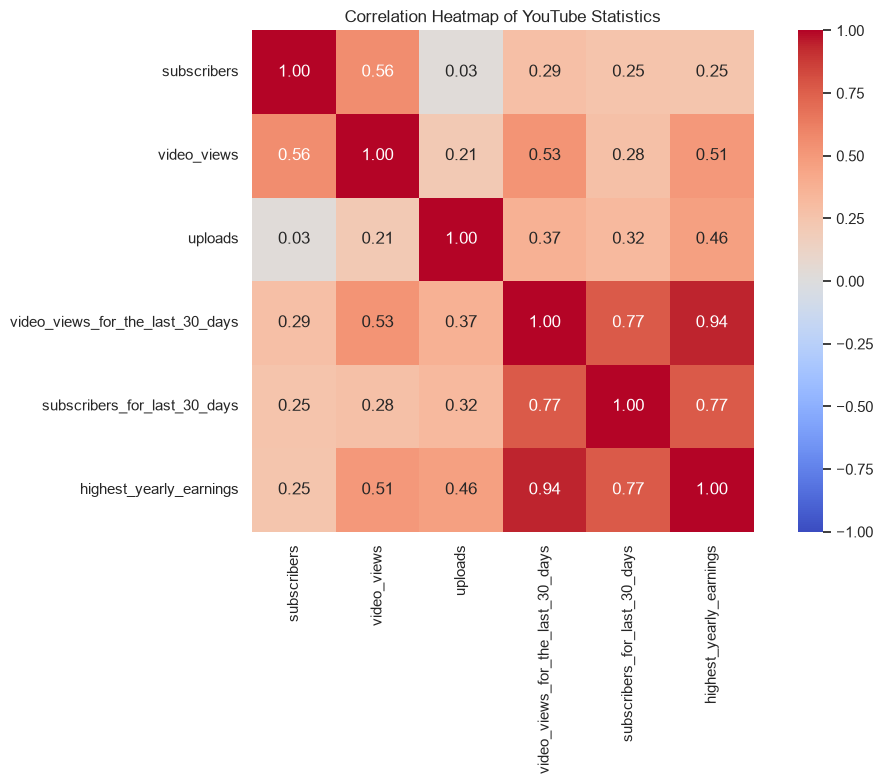

In [54]:
corr_cols = [
    "subscribers",
    "video_views",
    "uploads",
    "video_views_for_the_last_30_days",
    "subscribers_for_last_30_days",
    "highest_yearly_earnings"
]

corr_data = df[corr_cols].copy()

correlation = corr_data.corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap of YouTube Statistics")
plt.tight_layout()
plt.show()

### Correlation Analysis

The Spearman correlation analysis reveals the following relationships between YouTube channel metrics:

| Variable Pair | Correlation | Interpretation |
|---|---:|---|
| Subscribers vs. Video Views | 0.56 | Moderate positive association |
| Recent Views vs. Reported Subscriber Gain | 0.77 | Strong positive association |
| Recent Views vs. Highest Yearly Earnings Estimate | 0.94 | Very strong positive association |
| Uploads vs. Subscribers | 0.03 | Very weak monotonic association |

**Key Findings:**

- **Subscribers and video views:** A moderate positive association indicates that channels with more subscribers generally tend to have higher lifetime video views.
- **Recent views and subscriber gain:** A strong positive association suggests that channels receiving more recent views tend to report larger subscriber gains.
- **Recent views and estimated earnings:** A very strong positive association indicates that higher recent view counts are associated with higher estimated yearly earnings.
- **Uploads and subscribers:** The near-zero correlation suggests little monotonic association between upload count and subscriber count in this dataset.

**Conclusion:** Recent view counts show the strongest positive association among the examined variable pairs. However, these relationships do not establish causation, and estimated earnings should be interpreted cautiously because they may be calculated partly from view-related assumptions.